# Prior conflict as a negative control

**Level 3 — Research critique**  
**Prerequisites:** Levels 1–2 and inverse-problem fundamentals; 35 min.

## Objectives

Trace the evidence from source contract to result. State units and assumptions, reproduce the calculation, and identify which inference the evidence cannot support.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Data

Both 3D property models are synthetic, with coordinates and method metrics stored in the case receipts.

## Method

`JOINT_CONFLICT` is a synthetic negative control designed to violate shared structure. Compare coupled/independent RMSE ratios for density and susceptibility in both shared and conflict geometries; ratios above one mean worse recovery. Inspect WRMS and cross-gradient too: lowering the optimizer’s objective is not equivalent to recovering truth. A joint method is credible only where complementary data support the prior, with units/scales, independent baseline, withheld predictions, noise/coverage sensitivity and prior-conflict control. These cases inherit their generator, mesh and solver assumptions; they cannot establish field transfer, unsampled-cell resolution, or universal superiority. The control is useful precisely if it shows where structural coupling misleads.

The data operators have distinct units, coverage and null spaces. Cross-gradient penalties depend on discretization and scaling; parallel gradients do not imply equal amplitudes or shared geology everywhere. Compare predictions on each survey as well as truth error. Inspect units and masks before interpreting small ratio changes.

## State of the art

The research context is not a leaderboard: separate published formulation from the product implementation and its committed evidence. A claim of advance would require independent held-out domains, calibrated uncertainty and replication.

## Results

Read the physical axes and units; distinguish data fit, error against synthetic truth and agreement with analyst labels. Recomputed values must agree with the serialized receipt. A plotted model alone does not establish uniqueness, field transfer or resolution.

### Diagnostic 1

Inspect the committed case record and provenance.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Read shared-structure and prior-conflict controls and their saved method metrics.
import json
from pathlib import Path
cases={n:json.loads((root/f"data/derived/v2/{n}/regularization.json").read_text(encoding="utf-8")) for n in ("JOINT_SHARED","JOINT_CONFLICT")}
for n,d in cases.items():
 m=d["methods"]; a=m["joint-uncoupled"]["metrics"]; j=m["joint"]["metrics"]; print(n,"density ratio",j["model_rmse"]/a["model_rmse"],"magnetic ratio",j["magnetic_model_rmse"]/a["magnetic_model_rmse"],"joint WRMS",j["wrms"],j["magnetic_wrms"])

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
JOINT_SHARED density ratio 1.003881890836595 magnetic ratio 0.9966843553236885 joint WRMS 1.0834 1.045267
JOINT_CONFLICT density ratio 1.000531597688341 magnetic ratio 0.9977403254460245 joint WRMS 1.045473 1.039548


### Diagnostic 2

Compute the declared comparison and plot it with physical units.

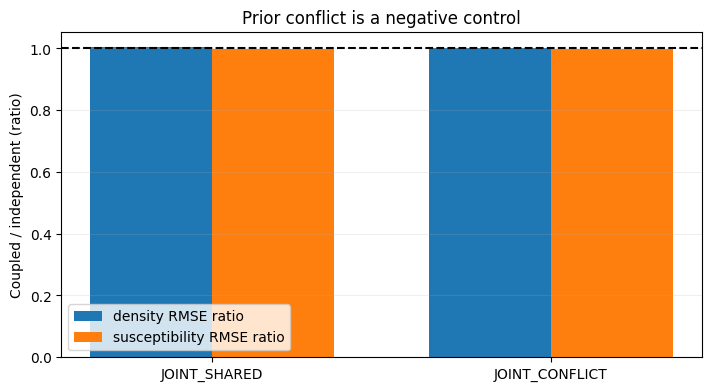

{'JOINT_SHARED': [1.003881890836595, 0.9966843553236885], 'JOINT_CONFLICT': [1.000531597688341, 0.9977403254460245]}


In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Ratios above one denote worse coupled model RMSE; compare both properties across controls.
import matplotlib.pyplot as plt
names=list(cases); vals=[]
for n in names:
 m=cases[n]["methods"]; a=m["joint-uncoupled"]["metrics"]; j=m["joint"]["metrics"]; vals.append([j["model_rmse"]/a["model_rmse"],j["magnetic_model_rmse"]/a["magnetic_model_rmse"]])
v=np.asarray(vals); x=np.arange(2); fig,ax=plt.subplots(figsize=(7,3.8),constrained_layout=True); ax.bar(x-.18,v[:,0],.36,label="density RMSE ratio"); ax.bar(x+.18,v[:,1],.36,label="susceptibility RMSE ratio"); ax.axhline(1,color="black",ls="--"); ax.set(xticks=x,xticklabels=names,ylabel="Coupled / independent (ratio)",title="Prior conflict is a negative control"); ax.legend(); ax.grid(axis="y",alpha=.2); plt.show(); print(dict(zip(names,v.tolist())))

## Summary

Conclusion is conditional on geometry, acquisition, noise model, split, parameterization and source rights. Preserve negative cases and name the next observation or control needed.

## References

- [https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)